# 4 · Generating molecules

## Goal

Put everything together on a generative task: learn a distribution over small molecules and sample new ones. By the end you will be able to combine a learned graph potential with knowledge written as code, train it with parallel tempering, and use the trained model to generate molecules, to steer generation towards a property, and to complete a partial molecule.

## Overview

A molecule is a relational structure: atoms are constants, their elements are unary predicates, and bonds are binary predicates. We learn a distribution over small molecules from 379 examples and generate new ones, the generative experiment of the original NMLN paper, in miniature.

Notebook 3 learned relational patterns with fragment potentials and Gibbs sampling. This one puts everything together:

1. **categorical relations**: a pair of atoms has at most one bond, of one type, the same in both directions;
2. a **graph neural potential**, which scores the whole molecule by message passing;
3. **knowledge written as code**: custom potentials for valence and connectivity, two constraints no fixed set of local rules expresses;
4. **parallel tempering**, for chains that must cross between valid molecules through invalid ones;
5. **generation**, **steering** (adding a potential at generation time) and **scaffold completion** (generation with evidence).

This notebook needs RDKit (`pip install -e ".[molecules]"`) and takes about three minutes on a laptop CPU.

In [1]:
import math
import random
from collections import Counter

import matplotlib.pyplot as plt
import torch
from IPython.display import display
from rdkit import Chem, RDLogger
from rdkit.Chem import Draw, rdMolDescriptors

import nmln

RDLogger.DisableLog("rdApp.*")  # RDKit explains every molecule it rejects; we count them instead
torch.manual_seed(0)
random.seed(0)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
DATA, MODEL, EXACT, NEURAL = "#9aa5b1", "#2563eb", "#dc2626", "#16a34a"

## 1. Molecules as worlds

Six atoms, the constants `0`…`5`. Each has one of six elements, the unary predicates `C`, `N`, `O`, `F`, `S`, `Cl`; each pair of atoms is linked by at most one bond, the binary predicates `SINGLE`, `DOUBLE`, `TRIPLE`.

Most combinations of atoms are not molecules, so we declare the variables (as for the digits of notebook 2, with `Categorical`):

- `Categorical(ATOM_TYPES)`: one variable per atom, whose value is its element; exactly one of `C(i)`, …, `Cl(i)` is true;
- `Categorical(BOND_TYPES, optional=True, symmetric=True, irreflexive=True)`: one variable per *unordered* pair of atoms, whose value is a bond type or `none`; `SINGLE(i,j)` and `SINGLE(j,i)` always agree, and no atom is bonded to itself.

We write molecules in **Kekulé form**: an aromatic ring is spelled out as alternating single and double bonds, so three bond types suffice and every bond has an integer order.

In [2]:
ATOM_TYPES = ["C", "N", "O", "F", "S", "Cl"]
BOND_TYPES = ["SINGLE", "DOUBLE", "TRIPLE"]
N_ATOMS = 6

atoms = nmln.Domain("atoms", [str(i) for i in range(N_ATOMS)])
ontology = nmln.Ontology(
    [atoms],
    [nmln.Predicate(name, [atoms]) for name in ATOM_TYPES] + [nmln.Predicate(name, [atoms, atoms]) for name in BOND_TYPES],
    variables=[nmln.Categorical(ATOM_TYPES),
               nmln.Categorical(BOND_TYPES, optional=True, symmetric=True, irreflexive=True)],
)
variables = ontology.variables
print(ontology.num_atoms, "ground atoms, grouped into", len(variables), "variables:")
print(f"  {variables.name(0):24s} values {variables.groups[0].values}  (6 such variables)")
print(f"  {variables.name(6):24s} values {variables.groups[1].values}  (15 such variables)")
print(f"{math.prod(variables.cardinalities.tolist()):,} possible worlds, against 2^{ontology.num_atoms} without the declarations")

144 ground atoms, grouped into 21 variables:
  C|N|O|F|S|Cl(0)          values ['C', 'N', 'O', 'F', 'S', 'Cl']  (6 such variables)
  SINGLE|DOUBLE|TRIPLE(0,1) values ['SINGLE', 'DOUBLE', 'TRIPLE', 'none']  (15 such variables)
50,096,498,540,544 possible worlds, against 2^144 without the declarations


## 2. The data: small molecules from ChEMBL

379 molecules with six heavy atoms (hydrogens are left implicit), as SMILES strings. RDKit reads them; we write each one as a world, and back. Every molecule survives the round trip.

379 molecules; 379 survive the round trip world → molecule
a world: ['C(1)', 'C(3)', 'C(4)', 'C(5)', 'N(0)', 'N(2)', 'SINGLE(1,2)', 'SINGLE(2,1)', 'SINGLE(2,3)', 'SINGLE(2,5)', 'SINGLE(3,2)', 'SINGLE(3,4)', 'SINGLE(4,3)', 'SINGLE(4,5)', 'SINGLE(5,2)', 'SINGLE(5,4)', 'TRIPLE(0,1)', 'TRIPLE(1,0)'] = N#CN1CCC1


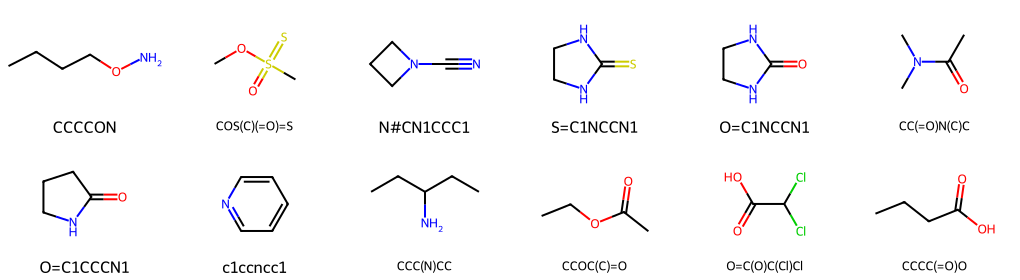

In [3]:
def to_world(molecule):
    molecule = Chem.Mol(molecule)
    Chem.Kekulize(molecule, clearAromaticFlags=True)
    y = torch.zeros(ontology.num_atoms)
    for atom in molecule.GetAtoms():
        y[ontology.atom_index(atom.GetSymbol(), atom.GetIdx())] = 1
    for bond in molecule.GetBonds():
        i, j, kind = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx(), str(bond.GetBondType())
        y[ontology.atom_index(kind, i, j)] = y[ontology.atom_index(kind, j, i)] = 1
    return y


def to_molecule(y):
    # The RDKit molecule of a world, or None if RDKit rejects it or it falls apart into several pieces.
    molecule = Chem.RWMol()
    for i in range(N_ATOMS):
        molecule.AddAtom(Chem.Atom(next(t for t in ATOM_TYPES if y[ontology.atom_index(t, i)] > 0.5)))
    for i, j in [(i, j) for i in range(N_ATOMS) for j in range(i + 1, N_ATOMS)]:
        for kind in BOND_TYPES:
            if y[ontology.atom_index(kind, i, j)] > 0.5:
                molecule.AddBond(i, j, getattr(Chem.BondType, kind))
    try:
        Chem.SanitizeMol(molecule)
    except Exception:
        return None
    return molecule if len(Chem.GetMolFrags(molecule)) == 1 else None


def show(molecules, legends=None, per_row=6, highlight=None):
    display(Draw.MolsToGridImage(molecules, molsPerRow=per_row, subImgSize=(170, 140), legends=legends,
                                 highlightAtomLists=highlight))


lines = open("../examples/molecules/chembl6.csv").read().splitlines()[1:]
data_smiles = [Chem.MolToSmiles(Chem.MolFromSmiles(line.split(",")[1])) for line in lines]
data = torch.stack([to_world(Chem.MolFromSmiles(s)) for s in data_smiles])
known = set(data_smiles)
print(len(data), "molecules;", sum(to_molecule(y) is not None for y in data), "survive the round trip world → molecule")
print("a world:", ontology.true_atoms(data[2]), "=", data_smiles[2])
show([Chem.MolFromSmiles(s) for s in data_smiles[:12]], legends=data_smiles[:12])

## 3. The potentials: one learned, two known

**A graph neural potential.** `GNNPotential` reads the world as a graph: the unary predicates are node features, each binary predicate is an edge type (plus one for "no bond"). A few rounds of relational message passing update the atoms' states, and a sum over atoms gives a single score. Like the fragment potentials of notebook 3, it does not depend on how the atoms are numbered; unlike them, it sees the whole molecule at once.

**Knowledge, written as code.** We also know two hard facts of chemistry:

- *valence*: the bond orders at an atom add up to at most its valence (4 for C, 3 for N, 2 for O, 1 for F and Cl, 6 for S);
- *connectivity*: a molecule is one piece.

Neither is a short logical rule. Valence is arithmetic on bond orders, and connectivity is reachability, a recursive property of the whole graph. Any potential can be written by hand: subclass `nmln.Potential` and implement `statistic(y, x)`. Here each statistic is 0 on worlds that respect the constraint and negative otherwise, with a large fixed weight, `learn_beta=False`, so that violations become very improbable.

In [4]:
MAX_VALENCE = {"C": 4, "N": 3, "O": 2, "F": 1, "S": 6, "Cl": 1}
BOND_ORDER = {"SINGLE": 1, "DOUBLE": 2, "TRIPLE": 3}


class ValencePotential(nmln.Potential):
    # statistic = - (total bond order in excess of the atoms' valences)

    def __init__(self, ontology, penalty):
        super().__init__(beta=penalty, learn_beta=False)
        allowed = torch.zeros(ontology.num_atoms, N_ATOMS)  # world → valence of every atom
        used = torch.zeros(ontology.num_atoms, N_ATOMS)     # world → bond order at every atom
        for i in range(N_ATOMS):
            for element, valence in MAX_VALENCE.items():
                allowed[ontology.atom_index(element, i), i] = valence
            for j in range(N_ATOMS):
                for kind, order in BOND_ORDER.items():
                    if i != j:
                        used[ontology.atom_index(kind, i, j), i] = order
        self.register_buffer("allowed", allowed)
        self.register_buffer("used", used)

    def statistic(self, y, x=None):
        return -torch.relu(y @ self.used - y @ self.allowed).sum(-1)


class ConnectedPotential(nmln.Potential):
    # statistic = -1 if some atom cannot be reached from atom 0 along bonds, else 0

    def __init__(self, ontology, penalty):
        super().__init__(beta=penalty, learn_beta=False)
        self.register_buffer("bonds", torch.stack([ontology.indices(kind) for kind in BOND_TYPES], -1))  # [6, 6, 3]

    def statistic(self, y, x=None):
        adjacency = y[..., self.bonds].sum(-1) + torch.eye(N_ATOMS, device=y.device)
        reachable = torch.linalg.matrix_power(adjacency, N_ATOMS - 1)[..., 0, :] > 0
        return -(~reachable).any(-1).float()


valence, connected = ValencePotential(ontology, penalty=30.0), ConnectedPotential(ontology, penalty=10.0)
examples = {f"{data_smiles[0]} (data)": data[0],
            "F bonded twice": to_world(Chem.MolFromSmiles("CCCCFC", sanitize=False)),
            "two pieces": to_world(Chem.MolFromSmiles("CCC.CCO"))}
for name, y in examples.items():
    print(f"{name:15s} valence statistic {int(valence.statistic(y)):2d}   connectivity statistic {int(connected.statistic(y)):2d}")

CCCCON (data)   valence statistic  0   connectivity statistic  0
F bonded twice  valence statistic -1   connectivity statistic  0
two pieces      valence statistic  0   connectivity statistic -1


## 4. Learning with parallel tempering

The model is the GNN plus the two knowledge potentials: $p(y) \propto \exp\big(\phi_{\text{GNN}}(y) - 30\cdot\text{excess valence}(y) - 10\cdot[\text{disconnected}(y)]\big)$. Only the GNN is trained; it learns what the knowledge leaves out.

Gibbs sampling changes one variable at a time, and between two valid molecules there are usually only invalid ones: to move a bond, first delete it (the molecule falls apart) or first add another (an atom exceeds its valence). At the model's temperature these intermediate worlds are very improbable, so a Gibbs chain rarely leaves the molecule it is in.

**Parallel tempering** runs replicas of the chains at temperatures $T_1 = 1 < T_2 < \dots$, each sampling from $p(y)^{1/T}$, with Gibbs sweeps inside each replica. Hot replicas see a flatter landscape and cross the barriers; after each sweep, neighboring replicas propose to swap their states, accepted with the Metropolis rule. Good states found by the hot replicas travel down to $T = 1$, whose chains are the samples.

We train with `Contrastive` learning on the persistent chains of a `ParallelTempering` engine, with the thesis's **training noise** (`noise_scale=0.1`: each variable of a data world is resampled with probability 0.1), and a smaller learning rate at the end, as in notebook 3. (About 45 seconds.)

In [5]:
TEMPERATURES = (1.0, 1.5, 2.5, 4.0)
loader = torch.utils.data.DataLoader(data, batch_size=32, shuffle=True)


def train(model):
    engine = nmln.ParallelTempering(model, temperatures=TEMPERATURES, sweeps_per_sample=20)
    learner = nmln.Contrastive(engine, lr=1e-3, noise_scale=0.1)
    learner.fit(loader, epochs=20, accelerator="cpu")
    learner.lr = 3e-4
    learner.fit(loader, epochs=10, accelerator="cpu")
    return engine


gnn = nmln.GNNPotential(ontology, ATOM_TYPES, BOND_TYPES, hidden_size=32)
model = nmln.NMLN(ontology, [gnn, valence, connected])
engine = train(model)
print("swap acceptance between neighboring temperatures (training chains):",
      engine.acceptance_rates(training=True).numpy().round(2))

swap acceptance between neighboring temperatures (training chains): [0.58 0.58 0.72]


## 5. Generating molecules

We draw 200 worlds from the target replica (each after 20 more sweeps) and turn them into molecules. Three standard numbers: **validity** (RDKit accepts the molecule and it is one piece), **uniqueness** (distinct valid molecules) and **novelty** (valid molecules that are not in the training data).

GNN + valence + connectivity valid 95.5%   unique 182   novel 167


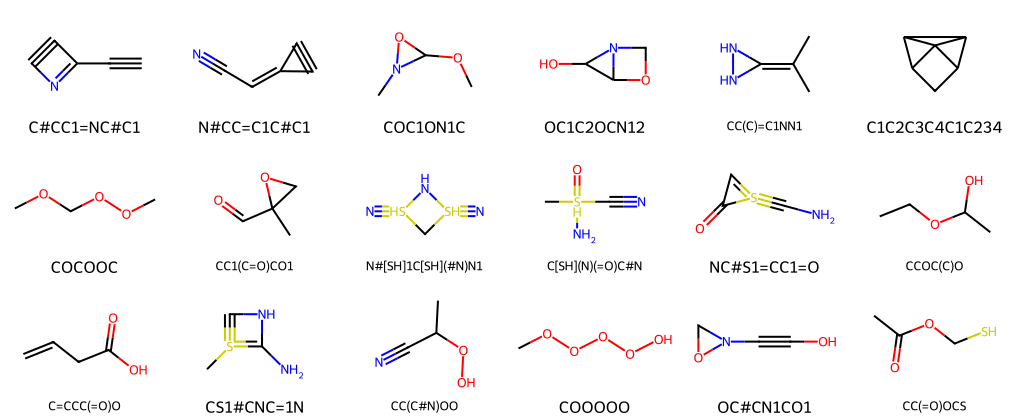

In [6]:
def report(worlds, label):
    smiles = [Chem.MolToSmiles(m) for m in map(to_molecule, worlds) if m is not None]
    unique = set(smiles)
    print(f"{label:28s} valid {len(smiles) / len(worlds):5.1%}   unique {len(unique):3d}   novel {len(unique - known):3d}")
    return smiles


samples = engine.sample(200)
generated = report(samples, "GNN + valence + connectivity")
novel = sorted(set(generated) - known)
picks = random.sample(novel, 18)
show([Chem.MolFromSmiles(s) for s in picks], legends=picks)

How close are the generated molecules to the data? We compare a few simple properties: how often each element appears, how many bonds of each type a molecule has, and how many rings.

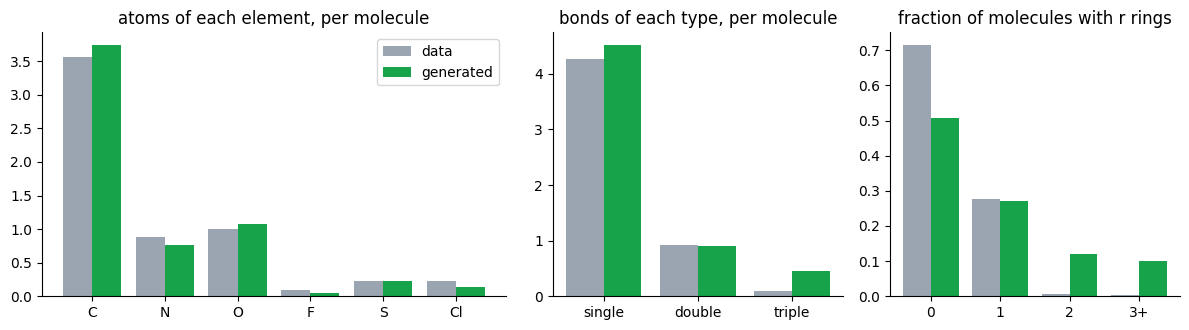

In [7]:
def properties(smiles_list):
    molecules = [Chem.MolFromSmiles(s) for s in smiles_list]
    worlds = torch.stack([to_world(m) for m in molecules])
    elements = torch.stack([worlds[:, ontology.indices(t)].sum(1) for t in ATOM_TYPES], 1).mean(0)
    bonds = torch.stack([worlds[:, ontology.indices(b).reshape(-1)].sum(1) / 2 for b in BOND_TYPES], 1).mean(0)
    rings = torch.bincount(torch.tensor([min(rdMolDescriptors.CalcNumRings(m), 3) for m in molecules]), minlength=4)
    return elements, bonds, rings / rings.sum()


fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.6, 1, 1]})
width = 0.4
for offset, (label, smiles, color) in zip([-width / 2, width / 2], [("data", data_smiles, DATA), ("generated", generated, NEURAL)]):
    elements, bonds, rings = properties(smiles)
    axes[0].bar(torch.arange(6) + offset, elements, width, color=color, label=label)
    axes[1].bar(torch.arange(3) + offset, bonds, width, color=color, label=label)
    axes[2].bar(torch.arange(4) + offset, rings, width, color=color, label=label)
axes[0].set(title="atoms of each element, per molecule", xticks=range(6), xticklabels=ATOM_TYPES)
axes[1].set(title="bonds of each type, per molecule", xticks=range(3), xticklabels=["single", "double", "triple"])
axes[2].set(title="fraction of molecules with r rings", xticks=range(4), xticklabels=["0", "1", "2", "3+"])
axes[0].legend()
plt.tight_layout()
plt.show()

Most generated molecules are valid and almost all are new: the model has learned a distribution, not a list. It reproduces how often each element appears and the numbers of single and double bonds, but it builds too many triple bonds and too many rings. Counting rings is hard for a message-passing network, and with 379 examples little tells it how rare fused rings are; the quantified and Deep-Set NMLNs of the presentation address exactly this kind of global statistic.

"Valid" means that RDKit accepts the valences, not that a chemist would: small rings with triple bonds or chains of oxygen atoms pass the check but would not survive long in a flask.

## 6. What the knowledge buys

Is the knowledge worth writing? We train the same GNN alone, with the same data and settings, and sort the worlds each model generates: valid, too many bonds at some atom, in several pieces, or rejected by RDKit for another reason.

GNN only                     valid 18.5%   unique  37   novel  35


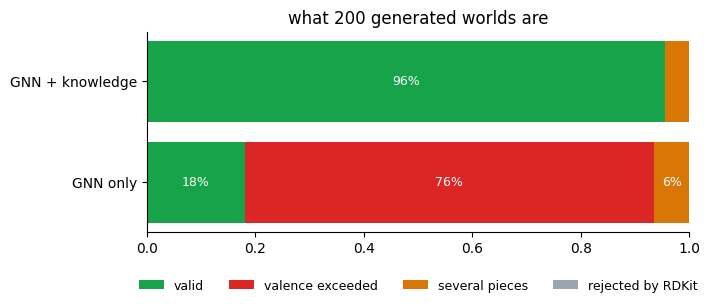

In [8]:
def verdicts(worlds):
    out = Counter()
    for y in worlds:
        if valence.statistic(y) < 0:
            out["valence exceeded"] += 1
        elif connected.statistic(y) < 0:
            out["several pieces"] += 1
        elif to_molecule(y) is None:
            out["rejected by RDKit"] += 1
        else:
            out["valid"] += 1
    return out


torch.manual_seed(1)
random.seed(1)
gnn_only = nmln.NMLN(ontology, [nmln.GNNPotential(ontology, ATOM_TYPES, BOND_TYPES, hidden_size=32)])
gnn_only_samples = train(gnn_only).sample(200)
report(gnn_only_samples, "GNN only")

kinds = ["valid", "valence exceeded", "several pieces", "rejected by RDKit"]
colors = [NEURAL, EXACT, "#d97706", DATA]
results = {"GNN only": verdicts(gnn_only_samples), "GNN + knowledge": verdicts(samples)}
plt.figure(figsize=(7, 2.6))
for row, (name, counts) in enumerate(results.items()):
    left = 0
    for kind, color in zip(kinds, colors):
        share = counts[kind] / len(samples)
        plt.barh(row, share, left=left, color=color, label=kind if row == 0 else None)
        if share > 0.06:
            plt.text(left + share / 2, row, f"{share:.0%}", ha="center", va="center", color="white", fontsize=9)
        left += share
plt.yticks(range(len(results)), list(results))
plt.xlim(0, 1)
plt.title("what 200 generated worlds are")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=False, fontsize=9)
plt.show()

The GNN alone has to learn valence and connectivity from 379 examples, and mostly doesn't: most of its worlds put too many bonds on some atom. Two short functions of background knowledge, combined with the learned potential in one model, fix that: symbolic and neural potentials are simply terms of the same score.

## 7. Why parallel tempering: a mixing diagnostic

How well do chains move between molecules? We start 50 fresh chains from the empty world, once with `Gibbs` and once with `ParallelTempering`, on the trained model, and count the distinct valid molecules each chain visits in 50 sweeps (after 10 sweeps of burn-in). Repeated `sample` calls continue the same chains, one sweep at a time.

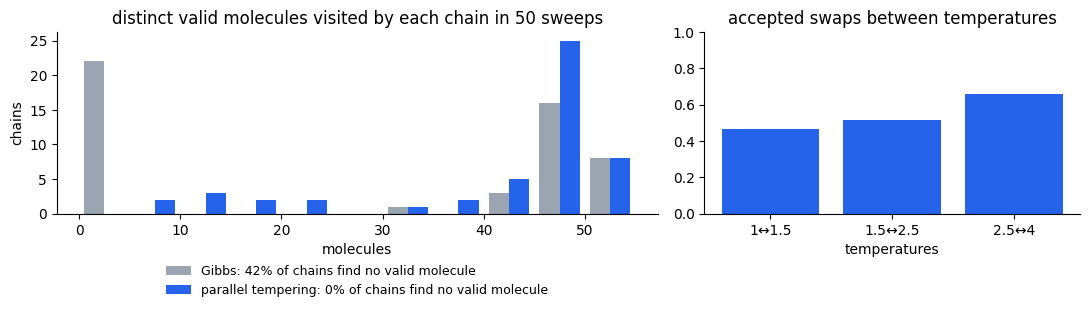

In [9]:
def explore(engine, chains=50, sweeps=60, burn_in=10):
    visited = [set() for _ in range(chains)]
    for sweep in range(sweeps):
        worlds = engine.sample(chains)
        if sweep >= burn_in:
            for chain, y in enumerate(worlds):
                molecule = to_molecule(y)
                if molecule is not None:
                    visited[chain].add(Chem.MolToSmiles(molecule))
    return torch.tensor([len(v) for v in visited])


tempering = nmln.ParallelTempering(model, temperatures=TEMPERATURES)
counts = {"Gibbs": explore(nmln.Gibbs(model)), "parallel tempering": explore(tempering)}

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
labels = [f"{name}: {(c == 0).float().mean():.0%} of chains find no valid molecule" for name, c in counts.items()]
left.hist(list(counts.values()), bins=torch.arange(0, 56, 5).tolist(), color=[DATA, MODEL], label=labels)
left.set(title="distinct valid molecules visited by each chain in 50 sweeps", xlabel="molecules", ylabel="chains")
left.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False, fontsize=9)
right.bar([f"{a:g}↔{b:g}" for a, b in zip(TEMPERATURES, TEMPERATURES[1:])], tempering.acceptance_rates(), color=MODEL)
right.set(title="accepted swaps between temperatures", ylim=(0, 1), xlabel="temperatures")
plt.tight_layout()
plt.show()

Started from the empty world, every chain must first build a connected molecule, and many Gibbs chains never manage it: they stay stuck in worlds that are several pieces. With parallel tempering, the hot replicas assemble molecules easily, and swaps (accepted about half of the time) hand them down to the target temperature, so every chain finds valid molecules. During training, the same mechanism provides the model samples, which is why we trained with it.

## 8. Steering generation

A trained model is a sum of potentials, so we can add another one at generation time, without retraining. To ask for molecules with at least three oxygen atoms, we add a potential that penalizes each missing oxygen: the new model is the old distribution reweighted towards what we asked for (a product of experts).

steered: at least 3 oxygens  valid 97.0%   unique  71   novel  68


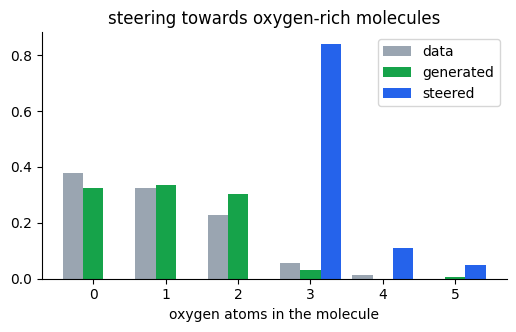

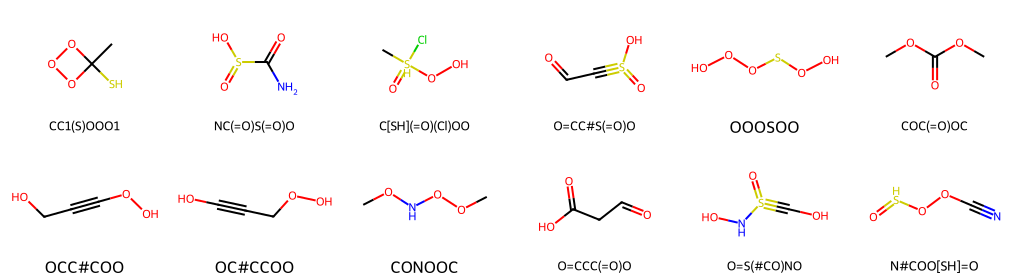

In [10]:
class AtLeastPotential(nmln.Potential):
    # statistic = - (number of atoms of an element missing to reach a minimum)

    def __init__(self, ontology, element, minimum, penalty):
        super().__init__(beta=penalty, learn_beta=False)
        self.register_buffer("element", ontology.indices(element))
        self.minimum = minimum

    def statistic(self, y, x=None):
        return -torch.relu(self.minimum - y[..., self.element].sum(-1))


steered_model = nmln.NMLN(ontology, [gnn, valence, connected, AtLeastPotential(ontology, "O", minimum=3, penalty=10.0)])
steered_samples = nmln.ParallelTempering(steered_model, temperatures=TEMPERATURES, sweeps_per_sample=40).sample(100)
steered = report(steered_samples, "steered: at least 3 oxygens")

oxygens = lambda worlds: torch.bincount(worlds[:, ontology.indices("O")].sum(1).long(), minlength=6)[:6]
width = 0.28
for offset, (label, worlds, color) in zip([-width, 0, width], [("data", data, DATA), ("generated", samples, NEURAL), ("steered", steered_samples, MODEL)]):
    c = oxygens(worlds)
    plt.bar(torch.arange(6) + offset, c / c.sum(), width, color=color, label=label)
plt.xlabel("oxygen atoms in the molecule")
plt.title("steering towards oxygen-rich molecules")
plt.legend()
plt.show()
picks = random.sample(sorted(set(steered)), 12)
show([Chem.MolFromSmiles(s) for s in picks], legends=picks)

The steered molecules have the oxygens we asked for and are still valid. The steering potential knows nothing about chemistry, though: the model fits the extra oxygens wherever its learned score allows, including in chains of oxygens.

## 9. Scaffold completion: generation with evidence

Conditional generation is inference with evidence, as in every notebook so far. We fix a carboxyl group, C(=O)O, on atoms 0, 1 and 2, and let the model complete the molecule. The evidence observes exactly the atoms of the **fragment** $\{0, 1, 2\}$ (notebook 3): the elements of the three atoms and the bonds among them. The other three atoms and every bond that touches them are free.

45 observed ground atoms: 18 for the elements of atoms 0-2, 27 for the bonds among them


completions of C(=O)O        valid 100.0%   unique  79   novel  64


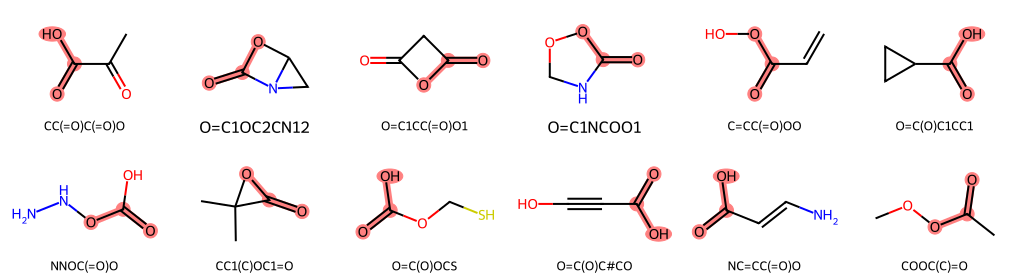

In [11]:
scaffold = ontology.world(["C(0)", "O(1)", "O(2)", "DOUBLE(0,1)", "DOUBLE(1,0)", "SINGLE(0,2)", "SINGLE(2,0)"])
observed = torch.zeros(ontology.num_atoms, dtype=torch.bool)
observed[ontology.fragment_indices(3)[0, 0]] = True  # the fragment of atoms (0, 1, 2), in their own order
elements = int(observed[torch.cat([ontology.indices(t) for t in ATOM_TYPES])].sum())
print(f"{int(observed.sum())} observed ground atoms: {elements} for the elements of atoms 0-2, {int(observed.sum()) - elements} for the bonds among them")

completions = engine.sample(100, evidence=nmln.Evidence(scaffold, observed))
completed = report(completions, "completions of C(=O)O")
worlds = {}
for y in completions:
    molecule = to_molecule(y)
    if molecule is not None:
        worlds.setdefault(Chem.MolToSmiles(molecule), molecule)
picks = random.sample(sorted(worlds), 12)
show([worlds[s] for s in picks], legends=picks, highlight=[[0, 1, 2]] * len(picks))

Every completion keeps the carboxyl group (highlighted) and adds three atoms around it: acids, esters, lactones, anhydrides, many of them molecules the model never saw.

## Summary

- **Categorical variables** with `optional`, `symmetric` and `irreflexive` describe bonds; the declarations cut the possible worlds from $2^{144}$ to about $5 \cdot 10^{13}$.
- A **GNN potential** scores a whole molecule, independently of how its atoms are numbered.
- **Knowledge can be code**: any `Potential` with a `statistic`. Valence and connectivity turn a GNN that generates mostly invalid worlds into one that generates mostly valid molecules.
- **Parallel tempering** lets chains cross the invalid worlds between valid molecules, during training and generation.
- A trained model can be **steered** by adding potentials, and **conditioned** with evidence, here a scaffold to complete.

## The tutorial in one table

| | notebook 1 | notebook 2 | notebook 3 | notebook 4 |
|---|---|---|---|---|
| language | one unary predicate | images as constants, built-ins | a binary relation | categorical relations |
| potentials | symbolic, world MLP | neural predicate + hard program | Markov logic, fragments | GNN + knowledge as code |
| inference | exact, Gibbs | exact belief propagation | Gibbs, conditional queries | parallel tempering, evidence |
| learning | maximum likelihood, contrastive | partial observations (only sums) | weights, then features | contrastive with training noise |

All of them are one model, $p(y \mid x) \propto \exp\big(\sum_k \beta_k\, \phi_k(y, x)\big)$, with different potentials and different engines.

## Exercises

1. Make the valence weight learnable: `ValencePotential(ontology, penalty=1.0)` with `learn_beta=True` in its `__init__`. What does contrastive learning do to it, and why? (Notebook 1, slide 53: the data never violate valence.)
2. Train on `chembl7.csv` (seven heavy atoms). What changes in validity and in training time?
3. Steer towards molecules without rings. Hint: a potential with the statistic of `ConnectedPotential` is a function of the adjacency matrix, and a molecule with $n$ atoms and no ring has $n - 1$ bonds.
4. Replace the GNN with `nmln.FragmentPotential(ontology, k=3)` from notebook 3. Which properties of section 5 get better or worse?